# 02. Replicating SVIX and the Probability of a Crash

Ian Martin's [*What is the Expected Return on the Market?*](https://academic.oup.com/qje/article/132/1/367/2724543)
(QJE 2017; the paper is in `papers/`) builds two numbers from index
option prices and publishes both on [his website](https://personal.lse.ac.uk/martiniw/):
**SVIX**, a volatility index like the VIX but with different weights on
the strikes, and the **probability of a 20% decline** in the S&P 500
over the coming month. CME computes the same construction every day as
its [CVOL](https://www.cmegroup.com/market-data/cme-group-benchmark-administration/cme-group-volatility-indexes.html)
family of volatility indexes, for options on its interest-rate, currency,
energy, metals, and agricultural futures. It publishes none for the
S&P 500, so Martin's own series is the benchmark here.

This guide rebuilds both numbers for one session and sets SVIX next to the
Cboe VIX. Guide 04 checks the SVIX integral against Martin's published
series over 1996 to 2012. There are three formulas, and they are the
three functions the homework asks you to complete: `svix.svix_squared`,
the Breeden-Litzenberger step in `rnd.risk_neutral_cdf`, and
`crash_prob.crash_probability`. Each gets a one-line derivation and a
picture. The pictures are the part to remember.

**In this guide**

1. From the smile to a priced grid.
2. SVIX²: add up the option prices.
3. The risk-neutral distribution: the slope of the call curve.
4. From risk-neutral to real: the log investor's crash probability.
5. Martin's published series, and CME's.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import crash_prob
import monitor
import pull_es_options
import pull_fred
import rnd
import smile
import svix
from settings import config

DATA_DIR = Path(config("DATA_DIR"))
MANUAL_DATA_DIR = Path(config("MANUAL_DATA_DIR"))
pd.set_option("display.width", 120)

options = pull_es_options.load_es_options()
fred = pull_fred.load_fred()
# The newest session the monitor computed a row for (a session it had to
# skip, a rare chain with too few usable strikes, is not shown here either).
computed = set(monitor.load_history()["date"]) & set(options["date"])
latest = max(computed) if computed else options["date"].max()
session = options[options["date"] == latest]
rate = pull_fred.rate_on(fred, latest)
near, far = smile.bracketing_expiries(session)
print(f"Session {latest.date()}; expirations {pd.Timestamp(near).date()} and {pd.Timestamp(far).date()} bracket 30 days; "
      f"one-month Treasury yield {100 * rate:.2f}%")

Session 2026-10-23; expirations 2026-10-30 and 2026-11-30 bracket 30 days; one-month Treasury yield 4.11%


## 1. From the smile to a priced grid

Guide 01 ended with the smile for one expiration: an implied volatility
at each out-of-the-money strike, with the strike written as moneyness
$k = K / S$. Both numbers below are integrals across strikes, and the
exchange's strikes are a discrete, uneven grid. So the engine
(`rnd.priced_grid`) interpolates the smile onto a fine grid of 2,000
points on $k \in [1/3, 3]$, linearly between observed strikes and flat
beyond them, and prices a call at every point with the Black-Scholes
formula. This is the recipe of Martin and Shi's Appendix D.

Units, once and for all. The spot is normalized to 1, so a strike and a
gross-return level are the same number $k$, an option price is a
fraction of the spot, the forward is $R_f = e^{r\tau}$, and the put at
$k$ follows from put-call parity, $p(k) = c(k) - 1 + k / R_f$.

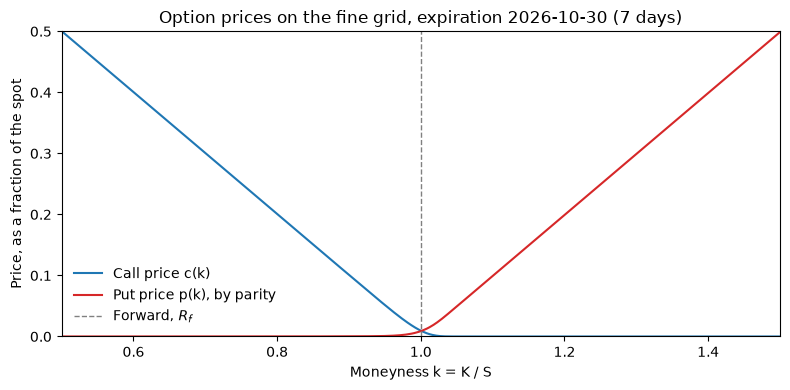

In [2]:
surface_near = smile.smile_for(options, latest, near, rate)
surface_far = smile.smile_for(options, latest, far, rate)
cdf_near = rnd.risk_neutral_cdf(surface_near, rate)
cdf_far = rnd.risk_neutral_cdf(surface_far, rate)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cdf_near.grid, cdf_near.call_grid, label="Call price c(k)", color="#1f77b4")
ax.plot(cdf_near.grid, cdf_near.put_grid, label="Put price p(k), by parity", color="#d62728")
ax.axvline(cdf_near.forward, color="gray", ls="--", lw=1, label="Forward, $R_f$")
ax.set_xlim(0.5, 1.5)
ax.set_ylim(0, 0.5)
ax.set_xlabel("Moneyness k = K / S")
ax.set_ylabel("Price, as a fraction of the spot")
ax.set_title(f"Option prices on the fine grid, expiration {pd.Timestamp(near).date()} ({int(surface_near['days_to_maturity'].iloc[0])} days)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 2. SVIX²: add up the option prices

**Risk-neutral probabilities.** Option prices do not reveal the market's
forecast of the return directly. They reveal the *risk-neutral*
probabilities, written $P^*$ and $E^*$ below: the probabilities under
which every asset's price is its discounted expected payoff, so that a
call struck at $k$ costs $c(k) = E^*[(R_T - k)^+] / R_f$. They differ
from the real-world probabilities because a dollar is worth more in a
crash than in a boom, and a price weights each state by that marginal
utility as well as by its likelihood. Section 4 undoes that weighting.

Martin defines SVIX² as the risk-neutral variance of the market's gross
return $R_T$, scaled by the risk-free rate and annualized (his equation
13):

$$\mathrm{SVIX}^2_t = \frac{1}{\tau}\,\mathrm{var}^*_t\!\left(\frac{R_T}{R_f}\right).$$

The point is that this variance is a sum of option prices. Two things to
remember:

- The price of any smooth payoff $g(R_T)$ can be built from a bond, a
  forward, and a strip of out-of-the-money options, where the option
  struck at $K$ gets weight $g''(K)$, the payoff's curvature there
  (Breeden and Litzenberger 1978, Carr and Madan 1998).
- The squared return has curvature 2 at every strike, so **every strike
  gets the same weight**. The VIX prices the log contract instead, whose
  curvature is $1/K^2$, so it overweights cheap, low strikes.

Applied to $g(R) = R^2$: $E^*[R_T^2]$ is $R_f^2$ plus $2 R_f$ times the
area under the out-of-the-money prices. Subtract the squared mean
$R_f^2$, divide by $R_f^2$ and by $\tau$, and the result is Martin's
equation (12), with the spot normalized to 1:

$$\mathrm{SVIX}^2 = \frac{2}{\tau\, R_f}\left[\int_0^{R_f} p(k)\,dk + \int_{R_f}^{\infty} c(k)\,dk\right].$$

Puts below the forward, calls above it, equal weights. CME's CVOL indexes
use the same construction for other markets. The integrand:

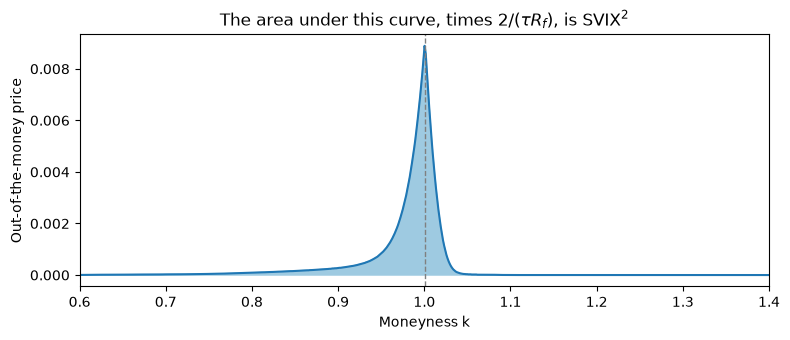

SVIX² at 7 days: 0.03340  ->  SVIX 18.28
SVIX² at 38 days: 0.03172  ->  SVIX 17.81
Interpolated to 30 days: SVIX² 0.03182  ->  SVIX 17.84
The VIX closed at 19.45 on 2026-10-23


In [3]:
grid = cdf_near.grid
otm = np.where(grid <= cdf_near.forward, cdf_near.put_grid, cdf_near.call_grid)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.fill_between(grid, otm, color="#9ecae1")
ax.plot(grid, otm, color="#1f77b4")
ax.axvline(cdf_near.forward, color="gray", ls="--", lw=1)
ax.set_xlim(0.6, 1.4)
ax.set_xlabel("Moneyness k")
ax.set_ylabel("Out-of-the-money price")
ax.set_title("The area under this curve, times $2 / (\\tau R_f)$, is SVIX$^2$")
fig.tight_layout()
plt.show()

month_expiry = smile.closest_expiry(session)  # the expiration closest to 30 days
cdf_month = {near: cdf_near, far: cdf_far}[month_expiry]
svix2_near = svix.svix_squared(cdf_near)
svix2_far = svix.svix_squared(cdf_far)
svix2_30 = svix.interpolate_variance(svix2_near, cdf_near.maturity_years, svix2_far, cdf_far.maturity_years)
# FRED publishes the VIX close a day later, so take the latest close on or before the session.
vix_obs = fred.dropna(subset=["vix"])
vix_obs = vix_obs[vix_obs["date"] <= latest].iloc[-1]
print(f"SVIX² at {int(surface_near['days_to_maturity'].iloc[0])} days: {svix2_near:.5f}  ->  SVIX {svix.svix_index(svix2_near):.2f}")
print(f"SVIX² at {int(surface_far['days_to_maturity'].iloc[0])} days: {svix2_far:.5f}  ->  SVIX {svix.svix_index(svix2_far):.2f}")
print(f"Interpolated to 30 days: SVIX² {svix2_30:.5f}  ->  SVIX {svix.svix_index(svix2_30):.2f}")
print(f"The VIX closed at {vix_obs['vix']:.2f} on {vix_obs['date'].date()}")

Two expirations rarely sit exactly 30 days out, so the two SVIX² values
are combined the way the VIX combines its two expirations: total
variance, SVIX² times $\tau$, is interpolated linearly to 30 days and
divided by 30 days. In VIX units, 100 times the square root, SVIX lands
below the VIX. Martin found the same in every year of his sample, and it
says something: if returns were lognormal, SVIX would sit slightly
*above* the VIX at a one-month horizon, so a VIX above SVIX is the
option market pricing a fat left tail, which the $1/K^2$ weights pick
up and the equal weights do not.

**A check against a closed form.** Under a flat smile the return is
lognormal, $\mathrm{var}^*(R/R_f) = e^{\sigma^2\tau} - 1$, and the
integral must give $(e^{\sigma^2\tau} - 1)/\tau$, a touch above
$\sigma^2$. That is the first test of `svix_squared`.

## 3. The risk-neutral distribution: the slope of the call curve

A call struck at $k$ pays $(R_T - k)^+$. Raise the strike by a little
and the payoff falls by that little in every state where the option
finishes in the money, and not at all elsewhere, so

$$\frac{dc}{dk} = -\frac{P^*(R_T > k)}{R_f}
\qquad\Longrightarrow\qquad
Q(k) \equiv P^*(R_T \le k) = 1 + R_f\,\frac{dc}{dk}.$$

This is Breeden and Litzenberger's result: the risk-neutral CDF is the
slope of the call curve, and the density is its curvature. On the fine
grid the slope is a numerical gradient. The raw result is not quite a
CDF: the interpolated smile has kinks at the observed strikes, so the
slope of the call curve jumps there, and where it jumps down the raw
$Q$ falls. An isotonic regression, the closest non-decreasing function,
fixes that, and a clip to $[0, 1]$ finishes the job. From here on the
horizon is one month, so the distribution is read off the expiration
closest to 30 days. Here are both, with the density:

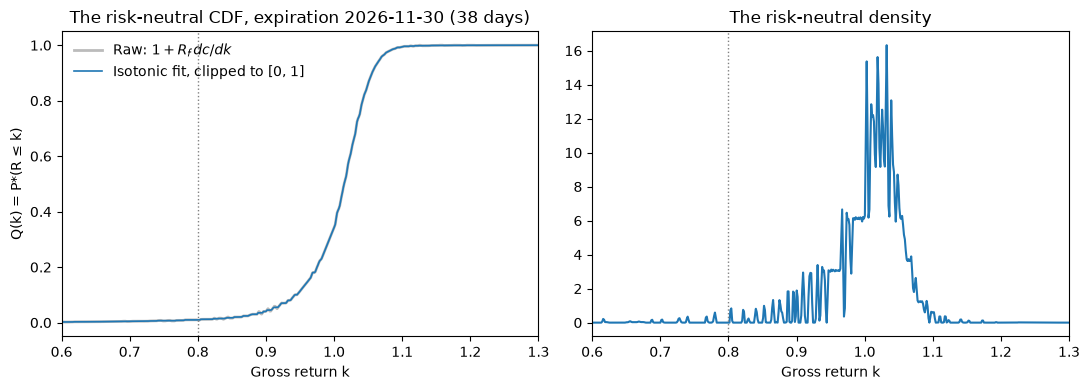

Risk-neutral probability of a 20% drop by 2026-11-30: 0.98%; of a 10% drop: 4.09%


In [4]:
grid = cdf_month.grid
R_f = cdf_month.forward
q_raw = 1.0 + R_f * np.gradient(cdf_month.call_grid, grid)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(grid, q_raw, color="#bbbbbb", lw=2, label="Raw: $1 + R_f\\, dc/dk$")
ax1.plot(grid, cdf_month.values, color="#1f77b4", lw=1.2, label="Isotonic fit, clipped to [0, 1]")
ax1.axvline(0.80, color="gray", ls=":", lw=1)
ax1.set_xlim(0.6, 1.3)
ax1.set_xlabel("Gross return k")
ax1.set_ylabel("Q(k) = P*(R ≤ k)")
ax1.set_title(f"The risk-neutral CDF, expiration {pd.Timestamp(month_expiry).date()} ({int(round(cdf_month.maturity_years * 365))} days)")
ax1.legend(frameon=False, loc="upper left")
density = np.gradient(cdf_month.values, grid)
ax2.plot(grid, density, color="#1f77b4")
ax2.axvline(0.80, color="gray", ls=":", lw=1)
ax2.set_xlim(0.6, 1.3)
ax2.set_xlabel("Gross return k")
ax2.set_title("The risk-neutral density")
fig.tight_layout()
plt.show()

p_star_20 = crash_prob.risk_neutral_crash_prob(cdf_month, 0.80)
p_star_10 = crash_prob.risk_neutral_crash_prob(cdf_month, 0.90)
print(f"Risk-neutral probability of a 20% drop by {pd.Timestamp(month_expiry).date()}: {100 * p_star_20:.2f}%; of a 10% drop: {100 * p_star_10:.2f}%")

The density has the shape every index option trader knows: a heavy left
tail, bought with the put smirk. $Q(0.8)$ is the risk-neutral
probability of a 20% drop: the number the options market charges for,
not the number it expects.

**Why the isotonic step is there.** Try the same derivative on the raw
settlement prices, strike by strike, without the smile and the fine grid:

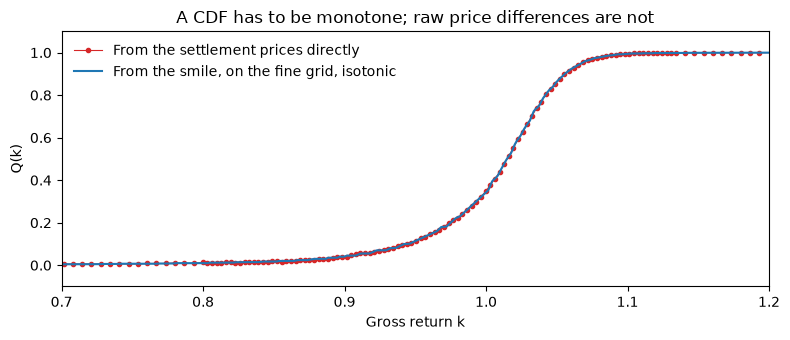

In [5]:
surface_month = {near: surface_near, far: surface_far}[month_expiry]
raw = session[(session["expiration"] == month_expiry) & (session["cp_flag"] == "C") & (session["settle"] > smile.MIN_SETTLE)].sort_values("strike")
spot = surface_month["spot_price"].iloc[0]
k_raw = raw["strike"].to_numpy() / spot
c_raw = raw["settle"].to_numpy() / spot
q_from_prices = 1.0 + R_f * np.gradient(c_raw, k_raw)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(k_raw, q_from_prices, ".-", color="#d62728", lw=0.8, label="From the settlement prices directly")
ax.plot(grid, cdf_month.values, color="#1f77b4", label="From the smile, on the fine grid, isotonic")
ax.set_xlim(0.7, 1.2)
ax.set_ylim(-0.1, 1.1)
ax.set_xlabel("Gross return k")
ax.set_ylabel("Q(k)")
ax.legend(frameon=False, loc="upper left")
ax.set_title("A CDF has to be monotone; raw price differences are not")
fig.tight_layout()
plt.show()

Settlement prices are marked strike by strike, to the tick, and their
differences are noisy; the "CDF" they give goes up and down.
OptionMetrics' smoothed surface hides this from you, because the vendor
has already fitted a smile. Working from the exchange's prices, you see
the problem and the cure.

**The test** of `risk_neutral_cdf` is the same flat-smile check: under a
constant volatility the CDF must be the lognormal's, in closed form.

## 4. From risk-neutral to real: the log investor's crash probability

$Q(0.8)$ overstates the chance of a crash, because a dollar in a crash
state is worth more than a dollar in a boom, and option prices weight
states by that marginal utility. Martin's way out (his Result 1) is to
take the perspective of an investor with log utility whose whole
portfolio is the market. Their marginal utility is $1/R_T$, so their
expectation of any payoff $X_T$ is the risk-neutral expectation of
$X_T R_T$, discounted:

$$E_t[X_T] = \frac{1}{R_f}\,E^*_t[X_T\, R_T].$$

Read it as: what a log investor would have to believe to be happy
holding the market. For the indicator of a crash,
$X_T = 1\{R_T \le \alpha\}$, the payoff $R_T\,1\{R_T \le \alpha\}$ is a
digital option minus a put, $\alpha\,1\{R_T \le \alpha\} - (\alpha - R_T)^+$,
and both pieces have prices on the grid: the digital costs
$Q(\alpha)/R_f$ and the put costs $p(\alpha)$. So (Martin's Result 2,
equation 23)

$$P_t(R_T \le \alpha) = \frac{\alpha\, Q(\alpha)}{R_f} - p(\alpha),$$

the risk-neutral probability, shrunk by the put's own price. Martin's
Figure VIII says the same thing as a picture: draw the tangent to the
put price curve at the crash strike, and it cuts the vertical axis at
$-P$. The crash probability is the convexity of the put curve at and
below $\alpha$.

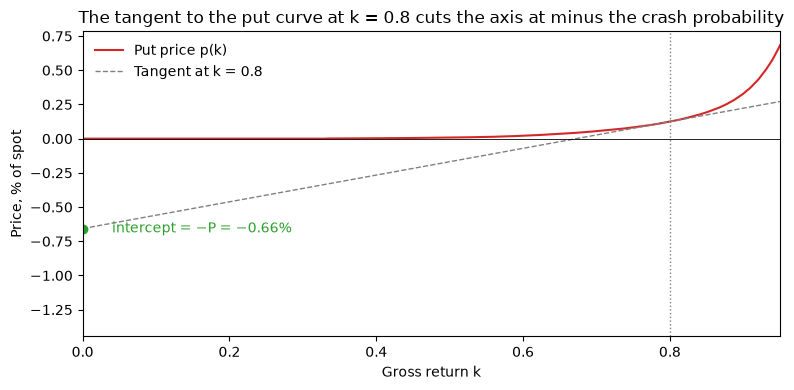

In [6]:
alpha = 0.80
P_log = crash_prob.crash_probability(cdf_month, alpha)
k_show = np.linspace(0.0, 0.95, 400)
put_show = np.interp(k_show, grid, cdf_month.put_grid, left=0.0)
tangent = cdf_month.put(alpha) + (cdf_month(alpha) / R_f) * (k_show - alpha)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_show, 100 * put_show, color="#d62728", label="Put price p(k)")
ax.plot(k_show, 100 * tangent, color="gray", ls="--", lw=1, label=f"Tangent at k = {alpha}")
ax.axhline(0, color="black", lw=0.6)
ax.axvline(alpha, color="gray", ls=":", lw=1)
ax.plot([0], [-100 * P_log], "o", color="#2ca02c")
ax.annotate(f"intercept = −P = −{100 * P_log:.2f}%", xy=(0, -100 * P_log), xytext=(0.04, -100 * P_log), va="center", color="#2ca02c")
ax.set_xlim(0, 0.95)
ax.set_ylim(-220 * P_log, 115 * put_show.max())
ax.set_xlabel("Gross return k")
ax.set_ylabel("Price, % of spot")
ax.set_title("The tangent to the put curve at k = 0.8 cuts the axis at minus the crash probability")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

Martin and Shi (2025) do the same for an investor with power utility and
risk aversion $\gamma$: weight by $R_T^\gamma$ instead of $R_T$ and
normalize, their equation (7),
$P = E^*[R_T^\gamma 1\{R_T \le \alpha\}] / E^*[R_T^\gamma]$. At
$\gamma = 1$ it is Martin's formula; they calibrate $\gamma = 2$. The
three numbers for this session:

In [7]:
rows = []
for label, alpha in [("20% drop", 0.80), ("10% drop", 0.90)]:
    rows.append({
        "event": f"{label} by {pd.Timestamp(month_expiry).date()}",
        "risk-neutral, P*": crash_prob.risk_neutral_crash_prob(cdf_month, alpha),
        "log investor (Martin 2017)": crash_prob.crash_probability(cdf_month, alpha),
        "power utility, gamma = 2 (Martin and Shi 2025)": crash_prob.crash_probability_power(cdf_month, alpha),
    })
pd.DataFrame(rows).set_index("event").style.format("{:.2%}")

,"risk-neutral, P*",log investor (Martin 2017),"power utility, gamma = 2 (Martin and Shi 2025)"
event,,,
20% drop by 2026-11-30,0.98%,0.66%,0.45%
10% drop by 2026-11-30,4.09%,3.34%,2.76%


The ordering is the content: the more risk-averse the investor, the more
of the option price is marginal utility rather than probability, and the
smaller the real-world probability they read out of it.

**The test** of `crash_probability`: under a flat smile the log
investor's probability has a closed form too,
$N\!\left((\ln a - s^2/2)/s\right)$ with $a = \alpha / R_f$ and
$s = \sigma\sqrt{\tau}$.

## 5. Martin's published series

Martin publishes SVIX² and the crash probability from January 1996 to
January 2012, computed from S&P 500 index options. Here is his SVIX next
to the VIX, and his monthly probability of a 20% drop at one month:

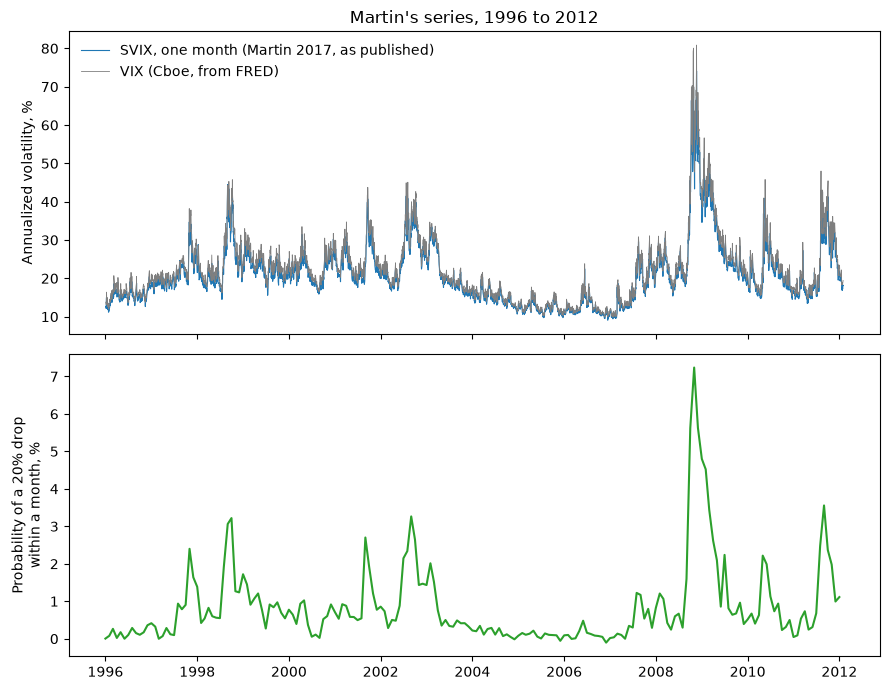

In [8]:
martin_svix = pd.read_csv(MANUAL_DATA_DIR / "martin_2017" / "svix2.csv", parse_dates=["date"])
martin_crash = pd.read_csv(MANUAL_DATA_DIR / "martin_2017" / "crashprob.csv")
martin_crash["date"] = pd.to_datetime(martin_crash[["year", "month"]].assign(day=1))
vix = fred.dropna(subset=["vix"])
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
ax1.plot(martin_svix["date"], 100 * np.sqrt(martin_svix["m1"]), label="SVIX, one month (Martin 2017, as published)", color="#1f77b4", lw=0.8)
v = vix[(vix["date"] >= martin_svix["date"].min()) & (vix["date"] <= martin_svix["date"].max())]
ax1.plot(v["date"], v["vix"], label="VIX (Cboe, from FRED)", color="#7f7f7f", lw=0.6)
ax1.set_ylabel("Annualized volatility, %")
ax1.legend(frameon=False)
ax1.set_title("Martin's series, 1996 to 2012")
ax2.plot(martin_crash["date"], 100 * martin_crash["m1"], color="#2ca02c")
ax2.set_ylabel("Probability of a 20% drop\nwithin a month, %")
fig.tight_layout()
plt.show()

The daily monitor of guide 03 continues the first chart from today
forward. Guide 04 recomputes both series from the OptionMetrics surface,
with the same `svix_squared` and `crash_probability` as here, and checks
them against these numbers: that is how the replication is tested, since
no exchange publishes an SVIX for the S&P 500.

## The homework

Part B asks for the three formulas derived here, in `src/svix.py`,
`src/rnd.py`, and `src/crash_prob.py`. Each function's docstring repeats
its formula, and `uv run pytest src/test_svix.py src/test_rnd.py src/test_crash_prob.py`
checks them offline against the closed forms. With the three in place,
`uv run doit` computes this session, and every session in the pull, into
the monitor's history, which is guide 03.